<a href="https://colab.research.google.com/github/nippysky/auto-mpg-fuel-efficiency-prediction/blob/main/Auto_MPG_Group13_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Predicting Vehicle Fuel Efficiency from Engine Specifications**

**1. Import the tools**

In [1]:
from pathlib import Path
from urllib.request import urlopen
import json
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

Path("data").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

**2. Load the official UCI data**

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
data_file = Path("data/auto-mpg.data")

if not data_file.exists():
    # Read the download completely before saving it.
    with urlopen(DATA_URL, timeout=30) as response:
        data_file.write_bytes(response.read())

column_names = [
    "mpg", "cylinders", "displacement", "horsepower", "weight",
    "acceleration", "model_year", "origin", "car_name"
]
df = pd.read_csv(data_file, sep=r"\s+", names=column_names, na_values="?")

assert df.shape == (398, 9), "Unexpected data shape: check the downloaded file."
assert df["mpg"].notna().all(), "The target should contain no missing values."
print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


**3. Check the structure and missing values**

In [3]:
df.info()
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate complete rows:", df.duplicated().sum())
print("Different car names:", df["car_name"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 28.1+ KB

Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Duplicate complete rows: 0
Different car names: 305


**4. Set aside the test data before detailed exploration**

In [4]:
X = df.drop(columns=["mpg", "car_name"])
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (318, 7) (318,)
Test: (80, 7) (80,)


**5. Explore the training data**

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
count,318.00,318.00,313.00,318.00,318.00,318.0,318.00,318.00
mean,5.43,191.90,103.28,2969.02,15.64,76.1,1.59,23.61
std,1.68,102.98,37.36,840.62,2.76,3.6,0.81,7.93
min,3.00,68.00,46.00,1613.00,8.00,70.0,1.00,9.00
25%,4.00,98.50,75.00,2220.00,13.90,73.0,1.00,17.50
50%,4.00,148.50,92.00,2822.50,15.50,76.0,1.00,22.45
75%,6.00,259.50,122.00,3597.25,17.30,79.0,2.00,29.72
max,8.00,455.00,225.00,5140.00,24.80,82.0,3.00,46.60


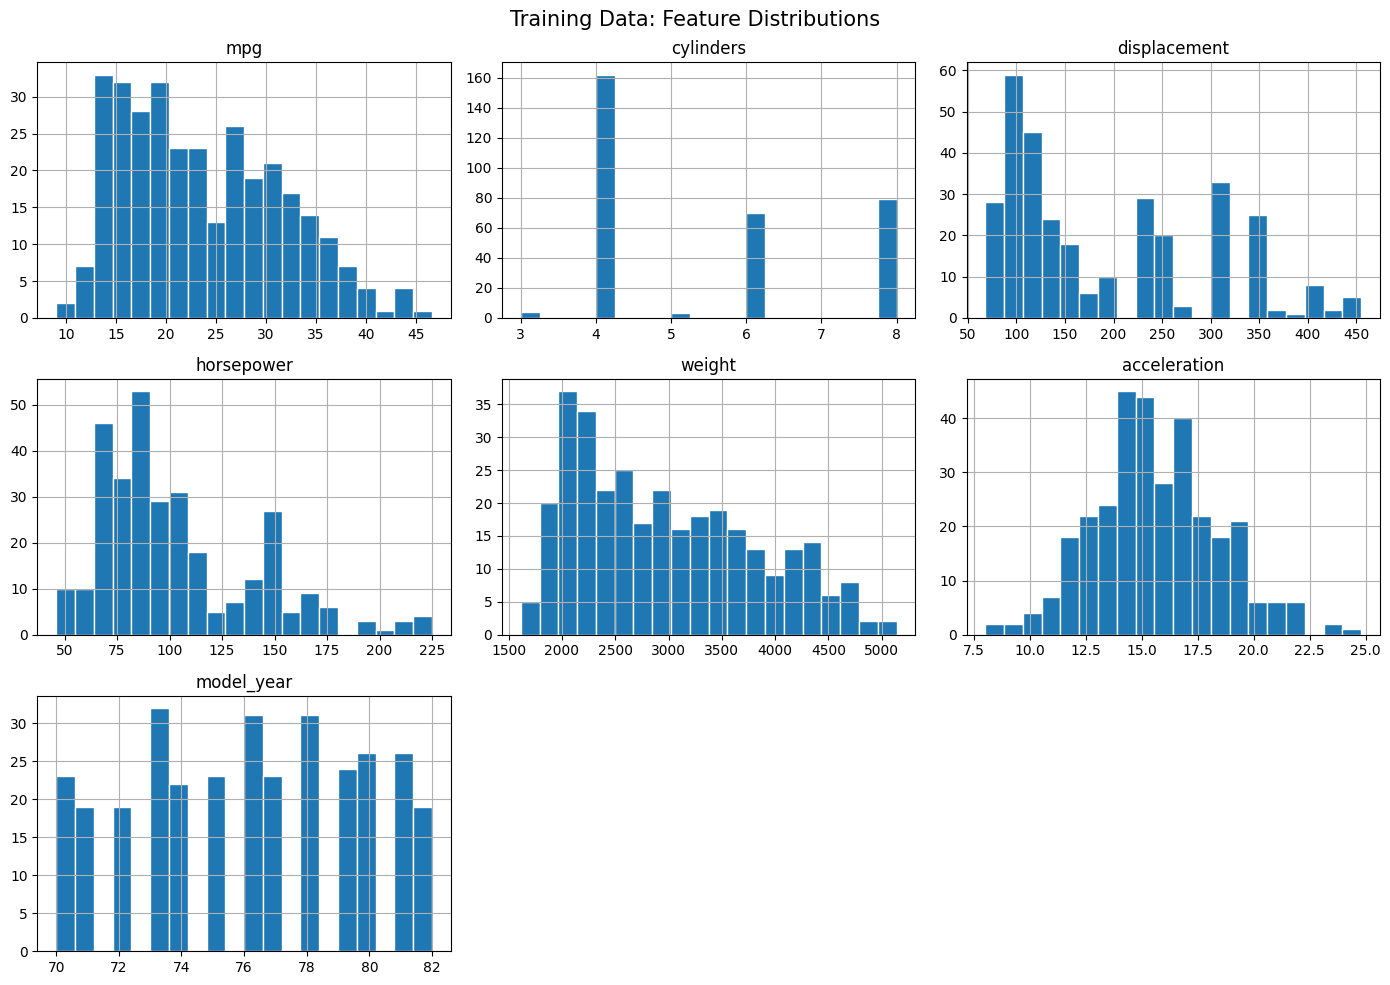

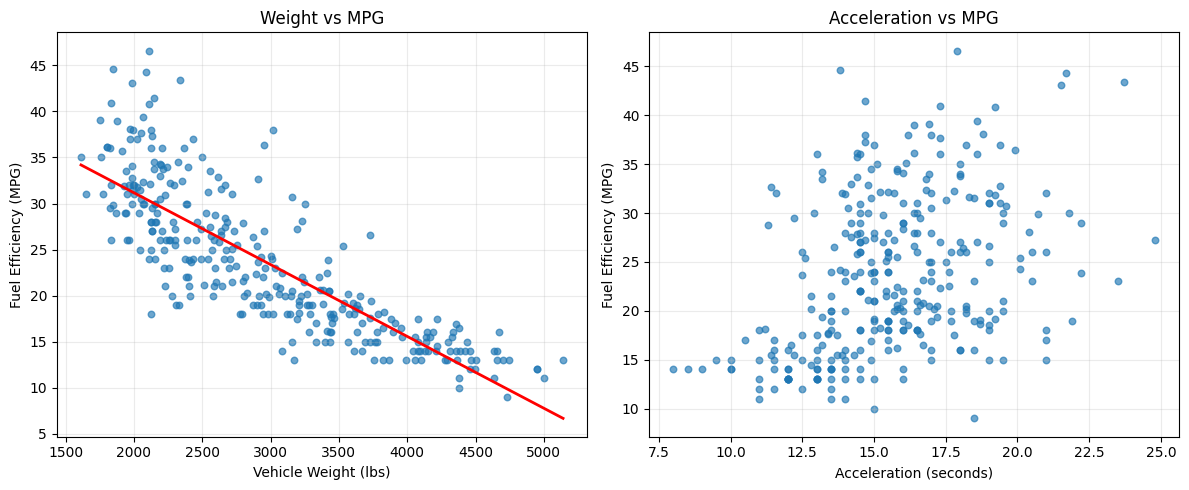

,mpg
weight,-0.827
displacement,-0.802
horsepower,-0.772
cylinders,-0.770
acceleration,0.390
model_year,0.587


Weight vs MPG correlation: -0.827
Acceleration vs MPG correlation: 0.39


In [5]:
train_data = X_train.copy()
train_data["mpg"] = y_train

display(train_data.describe().round(2))

# A. Histograms of the numerical features and MPG
hist_columns = [
    "mpg", "cylinders", "displacement",
    "horsepower", "weight", "acceleration", "model_year"
]

train_data[hist_columns].hist(
    bins=20,
    figsize=(14, 10),
    edgecolor="white"
)

plt.suptitle("Training Data: Feature Distributions", fontsize=15)
plt.tight_layout()
plt.savefig(
    "figures/feature_distributions.png",
    dpi=200, bbox_inches="tight"
)
plt.show()


# B. Relationships between vehicle features and MPG
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Weight vs MPG, including a linear trend line
axes[0].scatter(
    X_train["weight"], y_train,
    alpha=0.65, s=22
)

slope, intercept = np.polyfit(
    X_train["weight"], y_train, 1
)

weight_line = np.linspace(
    X_train["weight"].min(),
    X_train["weight"].max(), 100
)

axes[0].plot(
    weight_line,
    slope * weight_line + intercept,
    color="red", linewidth=2
)

axes[0].set(
    xlabel="Vehicle Weight (lbs)",
    ylabel="Fuel Efficiency (MPG)",
    title="Weight vs MPG"
)

# Acceleration vs MPG
axes[1].scatter(
    X_train["acceleration"], y_train,
    alpha=0.65, s=22
)

axes[1].set(
    xlabel="Acceleration (seconds)",
    ylabel="Fuel Efficiency (MPG)",
    title="Acceleration vs MPG"
)

for ax in axes:
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    "figures/feature_relationships.png",
    dpi=200, bbox_inches="tight"
)
plt.show()


# C. Correlation with MPG
# Origin is categorical, so exclude it.
correlations = (
    train_data.drop(columns="origin")
    .corr()["mpg"]
    .drop("mpg")
    .sort_values()
)

display(correlations.round(3))

print(
    "Weight vs MPG correlation:",
    round(train_data["weight"].corr(y_train), 3)
)

print(
    "Acceleration vs MPG correlation:",
    round(train_data["acceleration"].corr(y_train), 3)
)


**6. Define preprocessing, without fitting it yet**

In [6]:
numeric_features = [
    "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year"
]
categorical_features = ["origin"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessing = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("category", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

**7. Compare a baseline model with 3 other models (Linear Regression, Decision Tree, and Random Forest)**

In [7]:
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidate_pipelines = {}
rows = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preparation", clone(preprocessing)),
        ("model", clone(model)),
    ])
    fold_rmse = -cross_val_score(
        pipeline, X_train, y_train, cv=cv,
        scoring="neg_root_mean_squared_error", error_score="raise"
    )
    pipeline.fit(X_train, y_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, pipeline.predict(X_train)))
    candidate_pipelines[name] = pipeline
    rows.append({
        "Model": name,
        "Training RMSE": train_rmse,
        "CV RMSE mean": fold_rmse.mean(),
        "CV RMSE std": fold_rmse.std(),
    })

cv_results = pd.DataFrame(rows).sort_values("CV RMSE mean")
display(cv_results.round(3))

,Model,Training RMSE,CV RMSE mean,CV RMSE std
3,Random Forest,1.099,2.977,0.114
1,Linear Regression,3.370,3.478,0.224
2,Decision Tree,0.000,3.883,0.435
0,Mean baseline,7.918,7.923,0.557


**8. Tune the Random Forest using GridSearchCV**

In [8]:
parameter_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [1.0, "sqrt"]
}

search = GridSearchCV(
    estimator=clone(candidate_pipelines["Random Forest"]),
    param_grid=parameter_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    error_score="raise",
    refit=True
)

search.fit(X_train, y_train)

print("Best Random Forest hyperparameters:")
print(search.best_params_)

print(
    f"\nBest tuned cross-validation RMSE: "
    f"{-search.best_score_:.3f} MPG"
)

# Compare with the original untuned Random Forest
original_rmse = cv_results.loc[
    cv_results["Model"] == "Random Forest",
    "CV RMSE mean"
].iloc[0]

tuned_rmse = -search.best_score_

print(f"Original Forest CV RMSE: {original_rmse:.3f} MPG")
print(f"Tuned Forest CV RMSE: {tuned_rmse:.3f} MPG")
print(f"RMSE improvement: {original_rmse - tuned_rmse:.3f} MPG")

# Show the top-performing hyperparameter combinations
tuning_results = pd.DataFrame(search.cv_results_)

tuning_results["CV RMSE"] = -tuning_results["mean_test_score"]

display(
    tuning_results[
        ["params", "CV RMSE", "std_test_score"]
    ].sort_values("CV RMSE").head(10)
)


Best Random Forest hyperparameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 100}

Best tuned cross-validation RMSE: 2.907 MPG
Original Forest CV RMSE: 2.977 MPG
Tuned Forest CV RMSE: 2.907 MPG
RMSE improvement: 0.071 MPG


,params,CV RMSE,std_test_score
18,"{'model__max_depth': 10, 'model__max_features'...",2.906668,0.135893
19,"{'model__max_depth': 10, 'model__max_features'...",2.917039,0.131833
6,"{'model__max_depth': None, 'model__max_feature...",2.942166,0.095055
30,"{'model__max_depth': 20, 'model__max_features'...",2.942166,0.095055
31,"{'model__max_depth': 20, 'model__max_features'...",2.951038,0.124887
7,"{'model__max_depth': None, 'model__max_feature...",2.951038,0.124887
0,"{'model__max_depth': None, 'model__max_feature...",2.977443,0.113613
24,"{'model__max_depth': 20, 'model__max_features'...",2.977443,0.113613
25,"{'model__max_depth': 20, 'model__max_features'...",2.978751,0.113879
1,"{'model__max_depth': None, 'model__max_feature...",2.978751,0.113879


**9. Select the final model using validation results**

,Model,Training RMSE,CV RMSE mean,CV RMSE std
4,Random Forest (tuned),1.180,2.907,0.136
0,Random Forest,1.099,2.977,0.114
1,Linear Regression,3.370,3.478,0.224
2,Decision Tree,0.000,3.883,0.435
3,Mean baseline,7.918,7.923,0.557


Selected BEFORE test evaluation: Random Forest (tuned)

Final selected model: Random Forest (tuned)


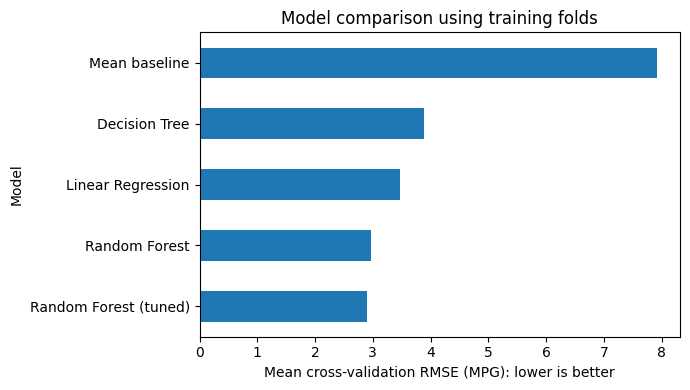

In [9]:
candidate_pipelines["Random Forest (tuned)"] = search.best_estimator_
tuned_train_prediction = search.best_estimator_.predict(X_train)
tuned_row = pd.DataFrame([{
    "Model": "Random Forest (tuned)",
    "Training RMSE": np.sqrt(mean_squared_error(y_train, tuned_train_prediction)),
    "CV RMSE mean": -search.best_score_,
    "CV RMSE std": search.cv_results_["std_test_score"][search.best_index_],
}])
selection_table = pd.concat([cv_results, tuned_row], ignore_index=True)
selection_table = selection_table.sort_values("CV RMSE mean")
display(selection_table.round(3))

best_name = selection_table.iloc[0]["Model"]
final_model = clone(candidate_pipelines[best_name])
final_model.fit(X_train, y_train)
print("Selected BEFORE test evaluation:", best_name)

print("\nFinal selected model:", best_name)


selection_table.plot.barh(x="Model", y="CV RMSE mean", legend=False, figsize=(7, 4))
plt.xlabel("Mean cross-validation RMSE (MPG): lower is better")
plt.title("Model comparison using training folds")
plt.tight_layout()
plt.savefig("figures/validation_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

**10. Inspect out-of-fold errors on the training set**

,actual_mpg,predicted_mpg,residual,absolute_error
387,38.0,19.93,18.07,18.07
333,32.7,21.68,11.02,11.02
329,44.6,34.48,10.12,10.12
364,26.6,17.22,9.38,9.38
244,43.1,34.40,8.70,8.70


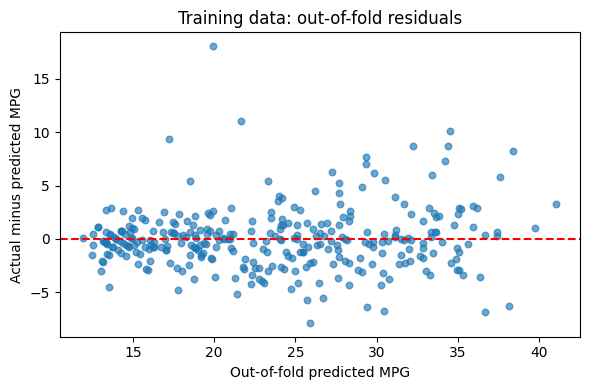

In [10]:
out_of_fold_prediction = cross_val_predict(final_model, X_train, y_train, cv=cv)
validation_errors = pd.DataFrame({
    "actual_mpg": y_train,
    "predicted_mpg": out_of_fold_prediction,
})
validation_errors["residual"] = validation_errors["actual_mpg"] - validation_errors["predicted_mpg"]
validation_errors["absolute_error"] = validation_errors["residual"].abs()
display(validation_errors.sort_values("absolute_error", ascending=False).head(5).round(2))

plt.figure(figsize=(6, 4))
plt.scatter(out_of_fold_prediction, validation_errors["residual"], alpha=0.65, s=22)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Out-of-fold predicted MPG")
plt.ylabel("Actual minus predicted MPG")
plt.title("Training data: out-of-fold residuals")
plt.tight_layout()
plt.savefig("figures/validation_residuals.png", dpi=200, bbox_inches="tight")
plt.show()

**11. Evaluate the fixed final model on the test set**

In [11]:
test_prediction = final_model.predict(X_test)
baseline_prediction = candidate_pipelines["Mean baseline"].predict(X_test)

test_rows = []
for name, prediction in [(best_name, test_prediction), ("Mean baseline", baseline_prediction)]:
    test_rows.append({
        "Model": name,
        "Test RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        "Test MAE": mean_absolute_error(y_test, prediction),
        "Test R2": r2_score(y_test, prediction),
    })
test_results = pd.DataFrame(test_rows)
display(test_results.round(3))

,Model,Test RMSE,Test MAE,Test R2
0,Random Forest (tuned),2.182,1.620,0.911
1,Mean baseline,7.347,5.955,-0.004


**12. Inspect the final predictions and errors**

,car_name,actual_mpg,predicted_mpg,residual,absolute_error
394,vw pickup,44.0,37.68,6.32,6.32
298,cadillac eldorado,23.0,17.32,5.68,5.68
377,mazda glc custom,31.0,35.98,-4.98,4.98
389,ford granada l,22.0,26.91,-4.91,4.91
238,dodge colt m/m,33.5,28.64,4.86,4.86


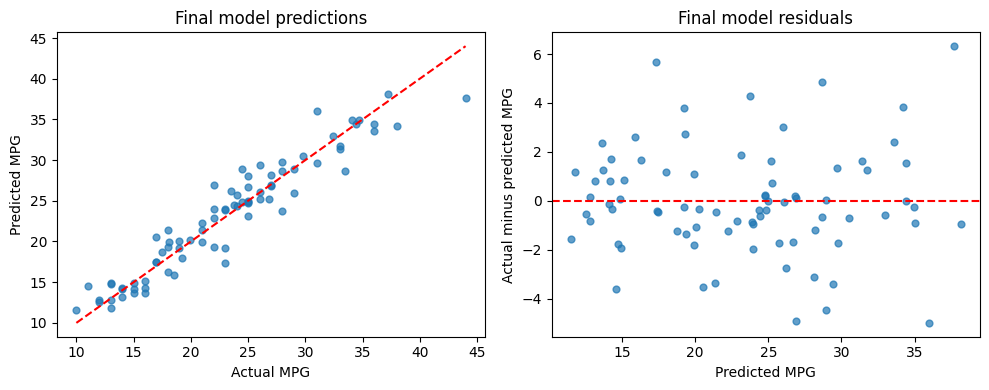

In [12]:
prediction_table = pd.DataFrame({
    "car_name": df.loc[X_test.index, "car_name"],
    "actual_mpg": y_test,
    "predicted_mpg": test_prediction,
})
prediction_table["residual"] = prediction_table["actual_mpg"] - prediction_table["predicted_mpg"]
prediction_table["absolute_error"] = prediction_table["residual"].abs()
display(prediction_table.sort_values("absolute_error", ascending=False).head(5).round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(y_test, test_prediction, alpha=0.7, s=24)
low = min(y_test.min(), test_prediction.min())
high = max(y_test.max(), test_prediction.max())
axes[0].plot([low, high], [low, high], "r--")
axes[0].set(xlabel="Actual MPG", ylabel="Predicted MPG", title="Final model predictions")
axes[1].scatter(test_prediction, prediction_table["residual"], alpha=0.7, s=24)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Predicted MPG", ylabel="Actual minus predicted MPG", title="Final model residuals")
plt.tight_layout()
plt.savefig("figures/final_predictions.png", dpi=200, bbox_inches="tight")
plt.show()

**13. Permutation Feature Importance of the Selected Final Model**

Permutation feature importance:


,Feature,RMSE Increase,Std
5,model_year,2.799,0.143
1,displacement,2.421,0.114
3,weight,1.954,0.085
2,horsepower,1.570,0.058
0,cylinders,1.385,0.079
4,acceleration,0.603,0.037
6,origin,0.493,0.030


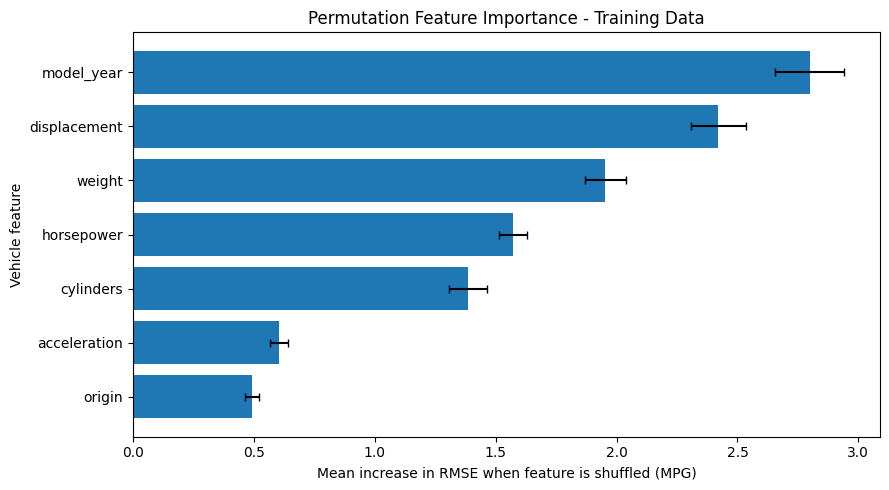

Feature importance analysis for: Random Forest (tuned)


In [13]:
importance = permutation_importance(
    final_model,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "RMSE Increase": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("RMSE Increase", ascending=False)

print("Permutation feature importance:")
display(feature_importance.round(3))

# Visualize relative feature importance
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["RMSE Increase"],
    xerr=feature_importance["Std"],
    capsize=3
)

plt.gca().invert_yaxis()
plt.axvline(0, color="gray", linewidth=0.8)
plt.xlabel("Mean increase in RMSE when feature is shuffled (MPG)")
plt.ylabel("Vehicle feature")
plt.title("Permutation Feature Importance - Training Data")

plt.tight_layout()
plt.savefig(
    "figures/feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print(f"Feature importance analysis for: {best_name}")

# Save the importance values
feature_importance.to_csv(
    "results/feature_importance.csv",
    index=False
)


**14. Predict MPG for a new vehicle**

In [14]:

# Hypothetical vehicle specifications.
# Origin codes: 1 = USA, 2 = Europe, 3 = Japan.

new_vehicle = pd.DataFrame([{
    "cylinders": 4,
    "displacement": 140.0,
    "horsepower": 90.0,
    "weight": 2400.0,
    "acceleration": 15.5,
    "model_year": 80,
    "origin": 2
}])

# Ensure the feature order matches training.
new_vehicle = new_vehicle[X_train.columns]

print("New vehicle specifications:")
display(new_vehicle)

predicted_mpg = final_model.predict(new_vehicle)[0]

print(f"Selected model: {best_name}")
print(f"Predicted fuel efficiency: {predicted_mpg:.2f} MPG")


New vehicle specifications:


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,4,140.0,90.0,2400.0,15.5,80,2


Selected model: Random Forest (tuned)
Predicted fuel efficiency: 31.55 MPG


**15. Save the results and record the environment**

In [15]:
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__,
}

selection_table.to_csv("results/validation_results.csv", index=False)
test_results.to_csv("results/test_results.csv", index=False)

prediction_table.to_csv(
    "results/test_predictions.csv", index_label="source_row"
)
validation_errors.to_csv(
    "results/validation_predictions.csv", index_label="source_row"
)

Path("results/environment.json").write_text(
    json.dumps(versions, indent=2),
    encoding="utf-8"
)

# Save the exact training and test row assignments.
pd.DataFrame({"source_row": X_train.index}).to_csv(
    "results/training_rows.csv", index=False
)
pd.DataFrame({"source_row": X_test.index}).to_csv(
    "results/test_rows.csv", index=False
)

print("Results saved successfully.")


Results saved successfully.
